# Compare OCR text checks
Choose your sequence below and select the **godfather.venv** kernel. Inspect each method independently: pyspellchecker dictionary coverage, NLTK dictionary coverage, and gibberish-detector character-pattern score. Both Magi and Paddle text are shown, with crops and Paddle confidence. OCR agreement strictly below 0.4 marks a box for deletion. Missing agreement is kept. Original OCR and crops remain visible; separate retained/deleted CSVs are exported. No corrections, narration model, or changes to pipeline caches.

## 1. Settings and existing-cache locations
This notebook first searches existing pipeline OCR caches by page image hash. If a page is missing, it creates its own OCR cache using your local Magi and Paddle models. The comparison resources live under `C:/MODELS/gibberish_detector`; only missing resources download when you run their setup cell.


In [1]:
import os,sys,json,hashlib,gc,math,re,string,subprocess,importlib.util
os.environ['HF_HUB_OFFLINE']='1'
os.environ['TRANSFORMERS_OFFLINE']='1'
import torch  # Before Paddle on this machine.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from difflib import SequenceMatcher

PROJECT=Path(r'C:\Users\ESHAAN\BYTE\Applied-Task\Magi')
SPLIT='development'
SEQUENCE_ID=' seq_06ec0acde37dffa4'
PAGE_NUMBER=1  # None = every page; otherwise the numeric page filename.
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
MAGI_MODEL=Path(r'C:\MODELS\magiv2')
PADDLE_DET_PATH=Path.home()/'.paddlex/official_models/PP-OCRv5_server_det'
PADDLE_REC_PATH=Path.home()/'.paddlex/official_models/en_PP-OCRv5_mobile_rec'
EXPERIMENT=PROJECT/'FINETUNING-EXPERMENTS/NarrationModelwBubbles'
CACHE_ROOTS=[EXPERIMENT/'cache_selected_ocr/full_pipeline',PROJECT/'paddleOCR-Magi/cache_inference']
CACHE=PROJECT/'paddleOCR-Magi/cache_gibberish_detection'
RESOURCE_DIR=Path(r'C:\MODELS\gibberish_detector')
GIB_MODEL=RESOURCE_DIR/'english.model'
CORPUS_PATH=RESOURCE_DIR/'big.txt'
NLTK_DATA=RESOURCE_DIR/'nltk_data'
DOWNLOAD_MISSING_RESOURCES=True
INSTALL_MISSING_PACKAGES=True
OCR_AGREEMENT_DELETE_BELOW=0.4  # Strictly below; missing agreement is not deleted.
GIB_THRESHOLD=4.0  # Library default, uncalibrated for manga. Always show the raw score.
MIN_GIB_LETTERS=3  # Shorter strings have too little evidence; display unavailable.
CUSTOM_WORDS=[]  # Optional names/interjections, applied to both dictionaries.
SAVE_RESULTS=True

# Ignore whitespace accidentally pasted with sequence IDs or split names.
SEQUENCE_ID=SEQUENCE_ID.strip()
SPLIT=SPLIT.strip()
sequence_folder=PROJECT/'TaskData'/SPLIT/'images'/SEQUENCE_ID
if not sequence_folder.is_dir():
    matches=[p for p in (PROJECT/'TaskData').glob('*/images/'+SEQUENCE_ID) if p.is_dir()]
    if len(matches)==1:
        sequence_folder=matches[0]
        SPLIT=sequence_folder.parent.parent.name
        print('Found sequence in split:',SPLIT)
    else:
        raise FileNotFoundError(f'Sequence folder not found: {sequence_folder}. Check SEQUENCE_ID and PROJECT. Matches: {matches}')
PAGE_FILES=sorted(p for p in sequence_folder.iterdir() if p.suffix.lower()=='.png')
available_pages=[p.name for p in PAGE_FILES]
if PAGE_NUMBER is not None:
    PAGE_NUMBER=int(PAGE_NUMBER)
    PAGE_FILES=[p for p in PAGE_FILES if p.stem.isdigit() and int(p.stem)==PAGE_NUMBER]
if not PAGE_FILES:
    raise FileNotFoundError(f'No selected PNG pages in {sequence_folder}. PAGE_NUMBER={PAGE_NUMBER}; available pages={available_pages}')
CACHE.mkdir(parents=True,exist_ok=True)
def file_hash(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def digest(value):return hashlib.sha256(json.dumps(value,sort_keys=True,ensure_ascii=True,allow_nan=False).encode()).hexdigest()
def read_payload(path):
    payload=json.loads(Path(path).read_text(encoding='utf-8'))
    assert digest(payload['data'])==payload['data_hash'],f'Invalid cache checksum: {path}'
    return payload['data']
print('Kernel:',sys.executable)
print('Pages:',[p.name for p in PAGE_FILES])


Kernel: c:\Users\ESHAAN\BYTE\godfather.venv\Scripts\python.exe
Pages: ['01.png']


## 2. Comparison packages
Use the existing kernel. Install only missing comparison packages into that kernel; no new environment is created. NLTK word lists and the gibberish model are loaded locally after the first setup. The gibberish score is a character-pattern score, **not a probability**; higher means less like its training corpus.


In [2]:
packages={'spellchecker':'pyspellchecker','nltk':'nltk','gibberish_detector':'gibberish-detector'}
missing=[package for module,package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    assert INSTALL_MISSING_PACKAGES, 'Missing packages: '+', '.join(missing)
    subprocess.check_call([sys.executable,'-m','pip','install',*missing])
from spellchecker import SpellChecker
import nltk
from gibberish_detector import detector,trainer,serializer
RESOURCE_DIR.mkdir(parents=True,exist_ok=True)
nltk.data.path.insert(0,str(NLTK_DATA))
try:
    nltk_words={w.lower() for w in nltk.corpus.words.words()}
except LookupError:
    assert DOWNLOAD_MISSING_RESOURCES,'Install NLTK words into '+str(NLTK_DATA)
    assert nltk.download('words',download_dir=str(NLTK_DATA),quiet=True,raise_on_error=True)
    nltk_words={w.lower() for w in nltk.corpus.words.words()}
nltk_words.update(w.lower() for w in CUSTOM_WORDS)
spell=SpellChecker(language='en')
spell.word_frequency.load_words([w.lower() for w in CUSTOM_WORDS])
if not GIB_MODEL.is_file():
    if not CORPUS_PATH.is_file():
        assert DOWNLOAD_MISSING_RESOURCES,'Set CORPUS_PATH to a local English training corpus.'
        import urllib.request
        url='https://raw.githubusercontent.com/domanchi/gibberish-detector/master/examples/big.txt'
        with urllib.request.urlopen(url,timeout=60) as response:
            corpus=response.read().decode('utf-8')
        CORPUS_PATH.write_text(corpus,encoding='utf-8')
    # Train once on an independent English corpus, never on the OCR being evaluated.
    corpus=CORPUS_PATH.read_text(encoding='utf-8').lower()
    model=trainer.train_on_content(corpus,string.ascii_lowercase)
    GIB_MODEL.write_text(serializer.serialize(model),encoding='utf-8')
    GIB_MODEL.with_suffix('.metadata.json').write_text(json.dumps(dict(
        corpus=str(CORPUS_PATH),corpus_sha256=file_hash(CORPUS_PATH),
        preprocessing='lowercase',charset=string.ascii_lowercase),indent=2),encoding='utf-8')
gib=detector.create_from_model(str(GIB_MODEL),limit=GIB_THRESHOLD)
print('Dictionary sizes:',len(spell.word_frequency.dictionary),len(nltk_words))
print('Local gibberish model:',GIB_MODEL)


Dictionary sizes: 160572 234377
Local gibberish model: C:\MODELS\gibberish_detector\english.model


## 3. Discover cached Magi + Paddle outputs
Each page must match its image hash, dimensions and payload checksum. Reuse cached OCR selections where possible, preserving original text IDs and reading order. Missing pages are collected for the next cell; this cell does not run any model.


In [3]:
def cached_page(path):
    sha=file_hash(path)
    with Image.open(path) as im: size=im.size
    for root in CACHE_ROOTS:
        for manifest_path in sorted(root.rglob('manifest.json')):
            try:
                manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
                matches=[i for i,p in enumerate(manifest['inputs']['pages'])
                         if p['sha256']==sha and (p['width'],p['height'])==size]
                if len(matches)!=1:continue
                index=matches[0]
                selection_path=manifest_path.with_name('ocr_selection.json')
                if selection_path.is_file():
                    page=read_payload(selection_path)[index]
                    if all(v['text_index']==i for i,v in enumerate(page)):
                        return [dict(box=v['box'],magi_text=v['magi_text'],paddle_text=v['paddle_text'],
                            paddle_lines=v.get('paddle_lines',[]),selected_text=v.get('selected_text',''),
                            paddle_status=v.get('paddle_status','cached'),paddle_error=v.get('paddle_error')) for v in page],str(selection_path)
                raw=read_payload(manifest_path.with_name('magi_raw.json'))[index]
                paddle=read_payload(manifest_path.with_name('paddle_ocr.json'))[index]
                if len(raw['texts'])!=len(paddle):continue
                if not all(v['box']==b for v,b in zip(paddle,raw['texts'])):continue
                return [dict(box=b,magi_text=t,paddle_text=v['text'],paddle_lines=v['lines'],
                    selected_text=None,paddle_status=v['status'],paddle_error=v.get('error'))
                    for b,t,v in zip(raw['texts'],raw['ocr'],paddle)],str(manifest_path.parent)
            except (OSError,KeyError,ValueError,AssertionError,IndexError,TypeError):
                continue
    return None,None

pages={}
for path in PAGE_FILES:
    records,source=cached_page(path)
    if records is not None:pages[str(path)]=dict(records=records,source=source)
    print('CACHE' if records is not None else 'MISSING',path.name,source or '')


CACHE 01.png C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\cache_selected_ocr\full_pipeline\development\seq_06ec0acde37dffa4\sequence\ocr_selection.json


## 4. Create missing OCR caches only
Skip automatically when existing OCR covers your sequence. Missing pages use local Magi detection/OCR and local Paddle on those Magi text crops. No YOLO, character fine-tuning or narration classifier is needed. Results go only to this notebook's cache folder.


In [4]:
def model_identity(path):
    return {str(p.relative_to(path)):[p.stat().st_size,p.stat().st_mtime_ns]
            for p in sorted(Path(path).rglob('*')) if p.is_file()
            and p.suffix in {'.json','.py','.bin','.safetensors','.pdparams','.pdiparams','.yml'}}

missing_pages=[p for p in PAGE_FILES if str(p) not in pages]
identity=None
if missing_pages:
    identity=dict(magi=str(MAGI_MODEL),magi_files=model_identity(MAGI_MODEL),
        paddle_det=str(PADDLE_DET_PATH),det_files=model_identity(PADDLE_DET_PATH),
        paddle_rec=str(PADDLE_REC_PATH),rec_files=model_identity(PADDLE_REC_PATH),algorithm=1)
    for path in list(missing_pages):
        cache_path=CACHE/(digest(dict(page=file_hash(path),models=identity))+'.json')
        if cache_path.is_file():
            try:
                pages[str(path)]=dict(records=read_payload(cache_path),source=str(cache_path))
                missing_pages.remove(path)
            except (OSError,ValueError,KeyError,AssertionError):pass

if missing_pages:
    from transformers import AutoConfig,AutoModel
    assert MAGI_MODEL.is_dir(),f'Missing Magi: {MAGI_MODEL}'
    config=AutoConfig.from_pretrained(str(MAGI_MODEL),trust_remote_code=True,local_files_only=True)
    config.detection_model_config.use_pretrained_backbone=False
    config.disable_ocr=False
    config.disable_detections=False
    model=AutoModel.from_pretrained(str(MAGI_MODEL),config=config,
        trust_remote_code=True,local_files_only=True).to(DEVICE).eval()
    raw_pages=[]
    try:
        for path in missing_pages:
            with Image.open(path) as im:array=np.asarray(im.convert('L').convert('RGB'))
            with torch.inference_mode():
                raw_pages.append(model.do_chapter_wide_prediction([array],{'images':[],'names':[]},do_ocr=True)[0])
    finally:
        del model
        gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    import paddle
    from paddleocr import PaddleOCR
    assert PADDLE_DET_PATH.is_dir() and PADDLE_REC_PATH.is_dir(),'Set local Paddle model directories.'
    engine=PaddleOCR(text_detection_model_name='PP-OCRv5_server_det',
        text_recognition_model_name='en_PP-OCRv5_mobile_rec',
        text_detection_model_dir=str(PADDLE_DET_PATH),text_recognition_model_dir=str(PADDLE_REC_PATH),
        device='gpu:0' if DEVICE=='cuda' else 'cpu',
        use_doc_orientation_classify=False,use_doc_unwarping=False,use_textline_orientation=False)
    try:
        for path,raw in zip(missing_pages,raw_pages):
            with Image.open(path) as im:im=im.convert('L').convert('RGB')
            records=[]
            for box,magi_text in zip(raw['texts'],raw['ocr']):
                a,b,c,d=box
                bounds=[max(0,math.floor(a)),max(0,math.floor(b)),min(im.width,math.ceil(c)),min(im.height,math.ceil(d))]
                lines=[];error=None
                try:
                    assert bounds[2]>bounds[0] and bounds[3]>bounds[1],'Invalid crop'
                    for prediction in engine.predict(input=np.asarray(im.crop(bounds))):
                        lines.extend(dict(text=str(t),confidence=float(s))
                            for t,s in zip(prediction['rec_texts'],prediction['rec_scores']))
                except Exception as exc:error=str(exc)
                records.append(dict(box=box,magi_text=magi_text,paddle_text=' '.join(v['text'] for v in lines),
                    paddle_lines=lines,selected_text=None,paddle_status='error' if error else 'text' if lines else 'empty',paddle_error=error))
            cache_path=CACHE/(digest(dict(page=file_hash(path),models=identity))+'.json')
            cache_path.write_text(json.dumps(dict(data=records,data_hash=digest(records)),indent=2,ensure_ascii=True),encoding='utf-8')
            pages[str(path)]=dict(records=records,source=str(cache_path))
            print('CREATED',path.name,cache_path)
    finally:
        del engine
        gc.collect()
        if DEVICE=='cuda':paddle.device.cuda.empty_cache()
print('Ready:',len(pages),'pages. Existing pipeline caches were not modified.')


Ready: 1 pages. Existing pipeline caches were not modified.


## 5. Independent scores for each OCR output
Dictionary coverage counts token occurrences, including repeats. Unknown words are displayed, never corrected. NLTK and pyspellchecker have different vocabularies; neither proves a text is valid. Punctuation-only text has no dictionary/gibberish score. The library's gibberish flag uses the threshold above and is shown separately from all other results. Short names, OCR spacing and interjections can fool these methods.


In [5]:
def score_text(text):
    text=str(text or '')
    tokens=re.findall(r"[a-z]+(?:'[a-z]+)?",text.lower().replace('’',"'"))
    unknown=spell.unknown(tokens)
    nltk_unknown={w for w in tokens if w not in nltk_words}
    letters=''.join(re.findall('[a-z]',text.lower()))
    score=gib.calculate_probability_of_being_gibberish(text.lower()) if len(letters)>=MIN_GIB_LETTERS else None
    word_scores=[dict(word=w,score=float(gib.calculate_probability_of_being_gibberish(w)))
                 for w in tokens if len(w)>=MIN_GIB_LETTERS]
    worst=max([v['score'] for v in word_scores],default=None)
    return dict(word_scores=word_scores,worst_word_score=worst,tokens=tokens,spell_unknown=sorted(unknown),nltk_unknown=sorted(nltk_unknown),
        spell_coverage=sum(w not in unknown for w in tokens)/len(tokens) if tokens else None,
        nltk_coverage=sum(w not in nltk_unknown for w in tokens)/len(tokens) if tokens else None,
        gibberish_score=score,gibberish_flag=bool(score>GIB_THRESHOLD) if score is not None else None)

def normalized(text):return ''.join(re.findall('[a-z0-9]',str(text).lower()))
rows=[]
for path in PAGE_FILES:
    for i,record in enumerate(pages[str(path)]['records']):
        confidences=[v['confidence'] for v in record['paddle_lines']]
        a,b=normalized(record['magi_text']),normalized(record['paddle_text'])
        row=dict(page=path.name,box_id=f'PG{int(path.stem)}:T{i+1}',text_index=i,
            magi_text=record['magi_text'],paddle_text=record['paddle_text'],
            selected_text=record['selected_text'],paddle_mean_confidence=float(np.mean(confidences)) if confidences else None,
            paddle_min_confidence=min(confidences) if confidences else None,
            ocr_agreement=SequenceMatcher(None,a,b).ratio() if a and b else None,
            paddle_status=record['paddle_status'],paddle_error=record['paddle_error'],
            bbox=record['box'],page_path=str(path),cache_source=pages[str(path)]['source'])
        for source in ['magi','paddle']:
            row.update({source+'_'+k:v for k,v in score_text(record[source+'_text']).items()})
        agreement=row['ocr_agreement']
        row['delete']=agreement is not None and agreement<OCR_AGREEMENT_DELETE_BELOW
        row['deletion_reason']='OCR agreement below 0.4' if row['delete'] else ''
        rows.append(row)
comparison=pd.DataFrame(rows)
columns=['box_id','delete','deletion_reason','magi_text','paddle_text','paddle_mean_confidence','ocr_agreement',
    'magi_spell_coverage','paddle_spell_coverage','magi_nltk_coverage','paddle_nltk_coverage',
    'magi_gibberish_score','paddle_gibberish_score','magi_gibberish_flag','paddle_gibberish_flag']
with pd.option_context('display.max_rows',None,'display.max_colwidth',100):
    display(comparison.reindex(columns=columns))
print('Deletion flags use only OCR agreement <',OCR_AGREEMENT_DELETE_BELOW,'. Original OCR remains available for review.')


,box_id,delete,deletion_reason,magi_text,paddle_text,paddle_mean_confidence,ocr_agreement,magi_spell_coverage,paddle_spell_coverage,magi_nltk_coverage,paddle_nltk_coverage,magi_gibberish_score,paddle_gibberish_score,magi_gibberish_flag,paddle_gibberish_flag
0,PG1:T1,False,,2-B,2-B,0.999836,1.000000,1.0,1.000000,1.000000,1.000000,NaN,NaN,None,None
1,PG1:T2,True,OCR agreement below 0.4,Letting this?,T -00 N9.o0,0.416757,0.222222,1.0,1.000000,0.500000,1.000000,2.065587,3.954399,False,False
2,PG1:T3,True,OCR agreement below 0.4,This site,t S 00 D 0 8,0.579656,0.266667,1.0,1.000000,1.000000,1.000000,2.041521,3.939043,False,False
3,PG1:T4,False,,We'll be filtering and grilling fish.,WE'LL BE FILLETING AND GRILLING FISH.,0.998614,0.933333,1.0,1.000000,0.666667,0.666667,2.459284,2.430073,False,False
4,PG1:T5,False,,UM...,UM...,0.986536,1.000000,1.0,1.000000,1.000000,1.000000,NaN,NaN,None,None
5,PG1:T6,False,,Our next class will be cooking practice.,OUR NEXT CLASS WILL BE COOKING PRACTICE.,0.993481,1.000000,1.0,1.000000,1.000000,1.000000,2.686394,2.686394,False,False
6,PG1:T7,False,,"The fish will be prepared here, so make sure to bring your aprons.","ThE FIsh WIll BE PREPARED HERE, SO MAKE SURE TO BRING YOUR APRONS.",0.933261,1.000000,1.0,1.000000,0.923077,0.923077,2.405684,2.405684,False,False
7,PG1:T8,True,OCR agreement below 0.4,It is,t3-3,0.747857,0.285714,1.0,1.000000,1.000000,1.000000,2.097209,NaN,False,None
8,PG1:T9,True,OCR agreement below 0.4,#85 (10)000 Family...every.,S<MONEO BEAIAREN.,0.533757,0.187500,1.0,0.333333,1.000000,0.333333,2.570674,2.651726,False,False
9,PG1:T10,False,,Cooking practice...,COOKING PRACTICE...,0.981706,1.000000,1.0,1.000000,1.000000,1.000000,2.508965,2.508965,False,False


Deletion flags use only OCR agreement < 0.4 . Original OCR remains available for review.


## Explore each method
Select the method and OCR source. Change the gibberish cutoff or compare the worst word instead of the whole-text average. These are inspection controls, not calibrated filtering rules. Dictionary outputs include unknown words. Slider changes are temporary; change GIB_THRESHOLD above and rerun scoring to update saved default flags.


In [ ]:
def compare_methods(method='All',source='Both',threshold=GIB_THRESHOLD,score_mode='Whole text',flagged_only=False):
    """Display independent results; the slider never deletes or corrects text."""
    sources=['magi','paddle'] if source=='Both' else [source.lower()]
    shown=[]
    for _,row in comparison.iterrows():
        for name in sources:
            score=row[name+'_gibberish_score'] if score_mode=='Whole text' else row[name+'_worst_word_score']
            available=score is not None and not pd.isna(score)
            flag=bool(score>threshold) if available else None
            item=dict(box_id=row['box_id'],source=name,text=row[name+'_text'],
                ocr_agreement=row['ocr_agreement'],delete=row['delete'],deletion_reason=row['deletion_reason'])
            if method in ['All','gibberish-detector']:
                item.update(score=score,threshold=threshold,gibberish_flag=flag,
                    word_scores=row[name+'_word_scores'])
            if method in ['All','pyspellchecker']:
                item.update(spell_coverage=row[name+'_spell_coverage'],unknown_words=row[name+'_spell_unknown'])
            if method in ['All','NLTK']:
                item.update(nltk_coverage=row[name+'_nltk_coverage'],nltk_unknown=row[name+'_nltk_unknown'])
            if method in ['All','OCR confidence / agreement']:
                item.update(paddle_mean_confidence=row['paddle_mean_confidence'] if name=='paddle' else None,
                    paddle_min_confidence=row['paddle_min_confidence'] if name=='paddle' else None,
                    ocr_agreement=row['ocr_agreement'])
            if flagged_only and method in ['All','gibberish-detector'] and flag is not True:continue
            shown.append(item)
    with pd.option_context('display.max_rows',None,'display.max_colwidth',120):
        display(pd.DataFrame(shown))
    if method in ['All','gibberish-detector']:
        print('Higher score = less English-like. Missing score = too few letters, not a False result.')
        print('Worst-word mode exposes odd words hidden by a sentence average; names may score high too.')

try:
    import ipywidgets as widgets
    controls=dict(method=widgets.Dropdown(options=['All','gibberish-detector','pyspellchecker','NLTK','OCR confidence / agreement'],description='Method:'),
        source=widgets.Dropdown(options=['Both','Magi','Paddle'],description='OCR:'),
        threshold=widgets.FloatSlider(value=GIB_THRESHOLD,min=0,max=max(8,GIB_THRESHOLD),step=.05,description='Cutoff:',continuous_update=False),
        score_mode=widgets.Dropdown(options=['Whole text','Worst word'],description='Score:'),
        flagged_only=widgets.Checkbox(value=False,description='Gibberish flags only'))
    output=widgets.interactive_output(compare_methods,controls)
    display(widgets.VBox(list(controls.values())),output)
except ImportError:
    compare_methods()
# Direct calls work without widgets:
# compare_methods('pyspellchecker')
# compare_methods('NLTK')
# compare_methods('gibberish-detector',threshold=3.5,score_mode='Worst word')


Output()

## 6. Crop viewer and contact sheet
Select a box to see its crop and each method's complete results. The contact sheet shows every text crop in original page/reading order. Both can be called directly if widgets are unavailable.


interactive(children=(Dropdown(description='Text box:', options=(('PG1:T1', 0), ('PG1:T2', 1), ('PG1:T3', 2), …

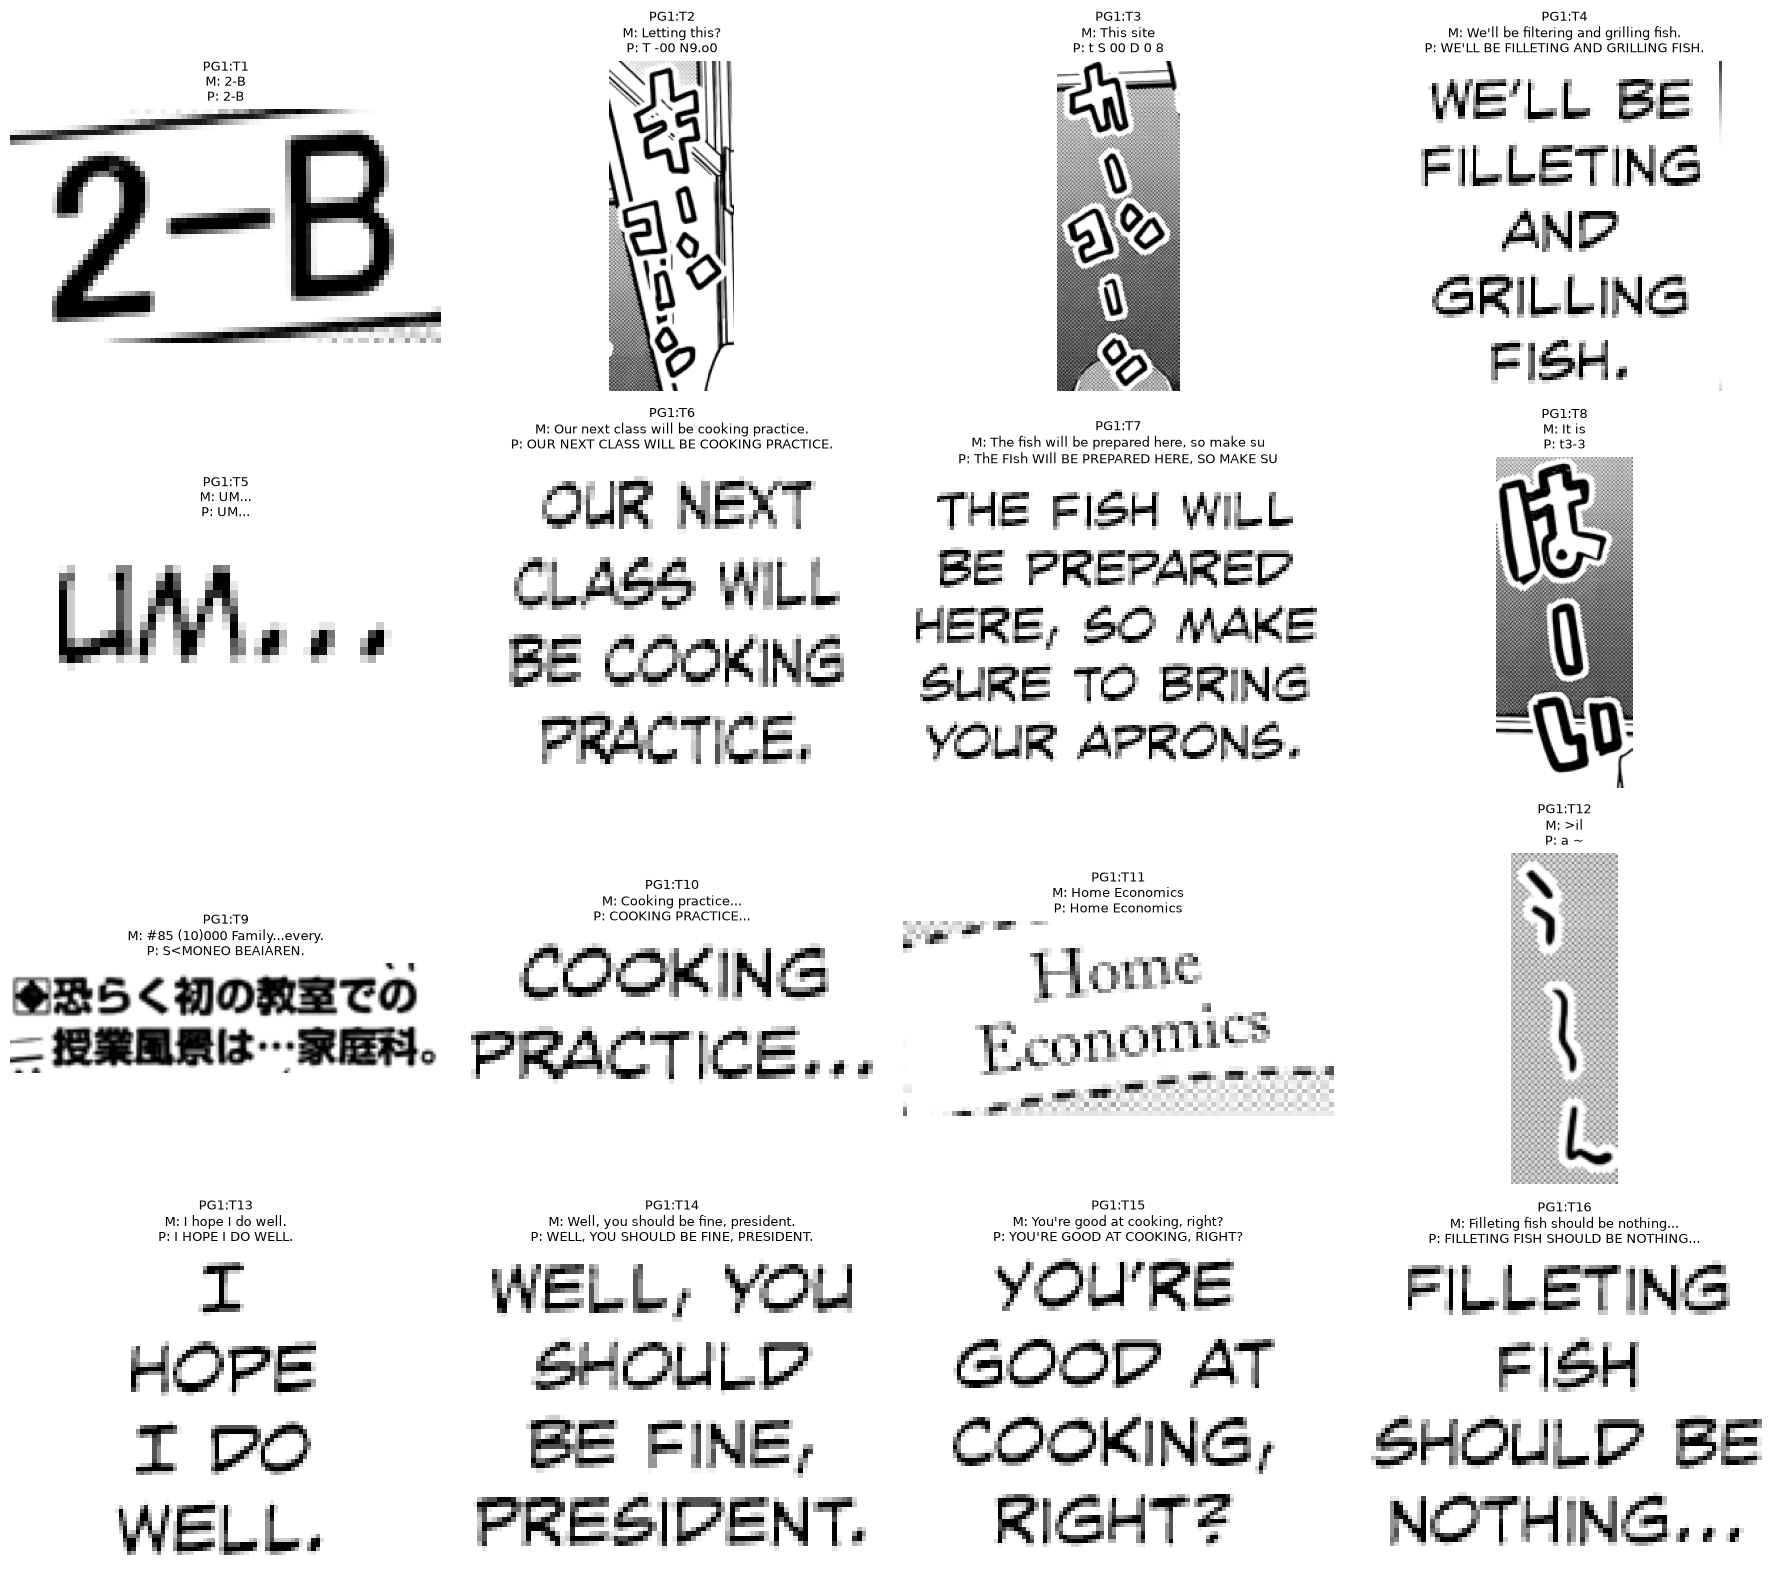

In [7]:
def inspect_box(index=0):
    if comparison.empty:print('No text boxes.');return
    row=comparison.iloc[index]
    with Image.open(row['page_path']) as im:
        a,b,c,d=row['bbox']
        crop=im.convert('RGB').crop((max(0,math.floor(a)),max(0,math.floor(b)),min(im.width,math.ceil(c)),min(im.height,math.ceil(d))))
    display(crop)
    display(pd.DataFrame([dict(source=source,text=row[source+'_text'],
        spell_coverage=row[source+'_spell_coverage'],spell_unknown=row[source+'_spell_unknown'],
        nltk_coverage=row[source+'_nltk_coverage'],nltk_unknown=row[source+'_nltk_unknown'],
        word_scores=row[source+'_word_scores'],worst_word_score=row[source+'_worst_word_score'],
        gibberish_score=row[source+'_gibberish_score'],gibberish_flag=row[source+'_gibberish_flag']) for source in ['magi','paddle']]))
    print('Delete:',row['delete'],'| Reason:',row['deletion_reason'])
    print('Paddle confidence:',row['paddle_mean_confidence'],'| OCR agreement:',row['ocr_agreement'])
    print('Paddle status:',row['paddle_status'],'| error:',row['paddle_error'])

if not comparison.empty:
    try:
        import ipywidgets as widgets
        selector=widgets.Dropdown(options=[(r['box_id'],i) for i,r in comparison.iterrows()],description='Text box:')
        display(widgets.interactive(inspect_box,index=selector))
    except ImportError:inspect_box(0)

def contact_sheet(start=0,count=20):
    subset=comparison.iloc[start:start+count]
    if subset.empty:return
    fig,axes=plt.subplots(math.ceil(len(subset)/4),4,figsize=(18,4*math.ceil(len(subset)/4)),squeeze=False)
    for ax,(_,row) in zip(axes.flat,subset.iterrows()):
        with Image.open(row['page_path']) as im:
            a,b,c,d=row['bbox']
            ax.imshow(im.convert('RGB').crop((max(0,math.floor(a)),max(0,math.floor(b)),min(im.width,math.ceil(c)),min(im.height,math.ceil(d)))))
        ax.set_title(row['box_id']+'\nM: '+str(row['magi_text'])[:42]+'\nP: '+str(row['paddle_text'])[:42],fontsize=9)
    for ax in axes.flat:ax.axis('off')
    fig.tight_layout();plt.show()
contact_sheet(0,20)
# contact_sheet(20,20) or inspect_box(0)


## 7. Save the comparison for your review
Comparison CSV and JSON retain every box, its deletion flag, and each method's separate results. `retained_ocr.csv` excludes boxes with OCR agreement below 0.4; `deleted_ocr.csv` contains those boxes for review. The resource hashes and thresholds are saved too. These are new inspection outputs; the inference pipeline and its transcripts are untouched.

Method references: [pyspellchecker](https://pyspellchecker.readthedocs.io/en/latest/quickstart.html), [NLTK corpora](https://www.nltk.org/howto/corpus.html), [gibberish-detector](https://github.com/domanchi/gibberish-detector).


In [8]:
if SAVE_RESULTS:
    output=CACHE/SPLIT/SEQUENCE_ID/('all_pages' if PAGE_NUMBER is None else f'page_{PAGE_NUMBER:02d}')
    output.mkdir(parents=True,exist_ok=True)
    comparison.to_csv(output/'comparison.csv',index=False)
    comparison.loc[~comparison['delete']].to_csv(output/'retained_ocr.csv',index=False)
    comparison.loc[comparison['delete']].to_csv(output/'deleted_ocr.csv',index=False)
    comparison.to_json(output/'comparison.json',orient='records',indent=2,force_ascii=False)
    from importlib.metadata import version
    metadata=dict(sequence_id=SEQUENCE_ID,split=SPLIT,pages=[dict(path=str(p),sha256=file_hash(p)) for p in PAGE_FILES],
        model=str(GIB_MODEL),model_sha256=file_hash(GIB_MODEL),threshold=GIB_THRESHOLD,min_gib_letters=MIN_GIB_LETTERS,
        ocr_agreement_delete_below=OCR_AGREEMENT_DELETE_BELOW,custom_words=CUSTOM_WORDS,nltk_word_count=len(nltk_words),
        packages={p:version(p) for p in packages.values()},kernel=sys.executable,
        note='Deletion flag: OCR agreement strictly below threshold. Full comparison retains every original box; retained/deleted CSVs are separate.')
    (output/'metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
    print('Saved:',output)


Saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\paddleOCR-Magi\cache_gibberish_detection\development\seq_06ec0acde37dffa4\page_01
